In [263]:
import torch
from sklearn.datasets import load_diabetes

In [264]:
# load a dataset from scikit-learn
diabetes = load_diabetes()
print(diabetes.keys())


dict_keys(['data', 'target', 'frame', 'DESCR', 'feature_names', 'data_filename', 'target_filename', 'data_module'])


In [265]:
import pandas as pd

df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target
df.head()


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [266]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns='target'), df['target'], test_size=0.2, random_state=42
)

In [267]:
X_train

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
17,0.070769,0.050680,0.012117,0.056301,0.034206,0.049416,-0.039719,0.034309,0.027364,-0.001078
66,-0.009147,0.050680,-0.018062,-0.033213,-0.020832,0.012152,-0.072854,0.071210,0.000272,0.019633
137,0.005383,-0.044642,0.049840,0.097615,-0.015328,-0.016345,-0.006584,-0.002592,0.017036,-0.013504
245,-0.027310,-0.044642,-0.035307,-0.029770,-0.056607,-0.058620,0.030232,-0.039493,-0.049872,-0.129483
31,-0.023677,-0.044642,-0.065486,-0.081413,-0.038720,-0.053610,0.059685,-0.076395,-0.037129,-0.042499
...,...,...,...,...,...,...,...,...,...,...
106,-0.096328,-0.044642,-0.076264,-0.043542,-0.045599,-0.034821,0.008142,-0.039493,-0.059471,-0.083920
270,0.005383,0.050680,0.030440,0.083844,-0.037344,-0.047347,0.015505,-0.039493,0.008641,0.015491
348,0.030811,-0.044642,-0.020218,-0.005670,-0.004321,-0.029497,0.078093,-0.039493,-0.010903,-0.001078
435,-0.012780,-0.044642,-0.023451,-0.040099,-0.016704,0.004636,-0.017629,-0.002592,-0.038460,-0.038357


In [268]:
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float64)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float64)

# Normalise targets so they're on the same scale as the features
y_mean = y_train_tensor.mean()
y_std = y_train_tensor.std()
y_train_tensor = (y_train_tensor - y_mean) / y_std



In [269]:
from torch.utils.data import TensorDataset, DataLoader

X_test_tensor = torch.tensor(X_test.values, dtype=torch.float64)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float64)
y_test_tensor = (y_test_tensor - y_mean) / y_std

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=32)


In [270]:
X_train_tensor.shape
# y_train_tensor.shape

torch.Size([353, 10])

In [271]:
# class DiabetesDataset:
#     def __init__(self):
#         pass 

#     def __len__():
#         return len()

#     def __get_item__():
#         pass

# diabetes = load_diabetes()
# X_train, X_test, y_train, y_test = train_test_split(
#     df.drop(columns='target'), df['target'], test_size=0.2, random_state=42
# )

# # diabetes

In [272]:
import torch.nn as nn


class Model(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(in_features=10, out_features=64, dtype=torch.float64),
            nn.Sigmoid(),
            nn.Linear(in_features=64, out_features=1, dtype=torch.float64),
        )

    def forward(self, batch):
        return self.layers(batch)


model = Model()


In [273]:
# test forward
model(torch.rand(size=(10,), dtype=torch.float64))

tensor([-0.5128], dtype=torch.float64, grad_fn=<ViewBackward0>)

In [274]:
loss = torch.nn.MSELoss()

In [275]:
optim = torch.optim.Adam(model.parameters(), lr=1e-3)


In [276]:
model.train()

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optim, patience=5, factor=0.5)
error_list = []
test_error_list = []

epochs = 500
for i in range(epochs):
    epoch_loss = 0.0
    test_loss = 0.0
    for data, label in train_loader:
        optim.zero_grad()
        pred = model(data).squeeze()
        error = loss(pred, label)
        error.backward()
        optim.step()
        epoch_loss += error.item()

    for data, label in test_loader:
        pred_eval = model(data).squeeze()
        test_loss += loss(pred_eval, label).item()

    epoch_loss /= len(train_loader)

    error_list.append(epoch_loss)
    test_error_list.append(test_loss / len(test_loader))
    scheduler.step(epoch_loss)

model.eval()


Model(
  (layers): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [277]:
error_list

[1.1206808359892353,
 0.9873179306027174,
 0.9970755316033525,
 0.9937818629849727,
 0.9859083239180711,
 0.9829378246735598,
 0.9818938526996668,
 0.979797129612631,
 0.9724817809495936,
 0.9657250943144944,
 0.9714262682741327,
 0.9660146817015852,
 0.9598326880066387,
 0.9578172976057253,
 0.9555667108204414,
 0.9486644426666427,
 0.946880850937405,
 0.9355560348319295,
 0.9403958543898163,
 0.9328992971300223,
 0.9324392467911828,
 0.9314234712159931,
 0.9215911350265841,
 0.9136054397572853,
 0.9167082245877808,
 0.9069515677974568,
 0.9137863153861534,
 0.904277605417952,
 0.9009400180635965,
 0.8947867970105187,
 0.8845511635021459,
 0.8828180600339105,
 0.8781117100846952,
 0.8727309061423113,
 0.8661173689880783,
 0.8568225828295514,
 0.8527616033313291,
 0.8542358528522332,
 0.8424003738601008,
 0.8381727395361728,
 0.8284858668817052,
 0.8235857564207687,
 0.8155475183244145,
 0.8110506437540459,
 0.8077020209411139,
 0.804307318484468,
 0.7926156488120687,
 0.78878797812647

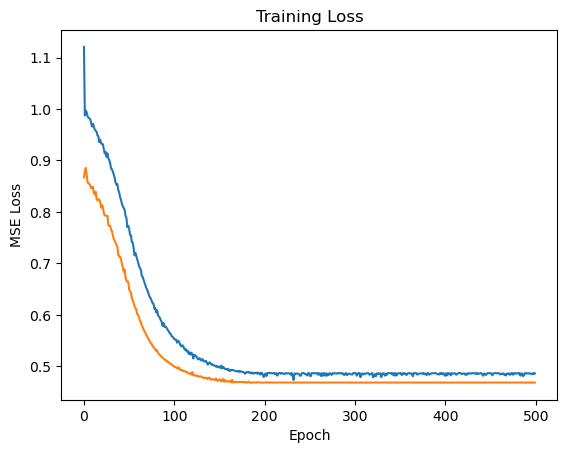

In [279]:
import matplotlib.pyplot as plt

plt.plot(error_list)
plt.plot(test_error_list)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")
plt.show()


89


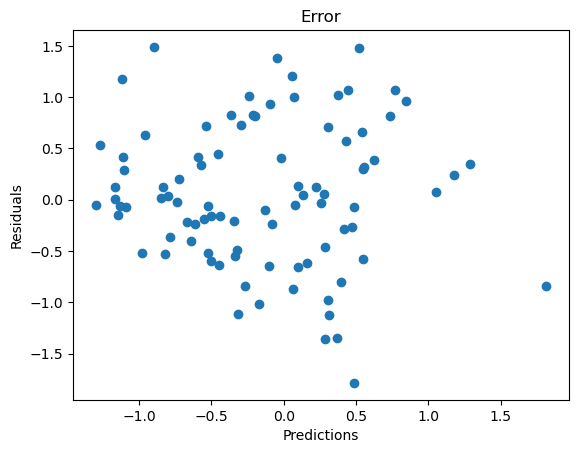

In [281]:
residuals = [] # y_axis
predictions = []
for i in range(len(y_test_tensor)):
    pred = model(X_test_tensor[i]).squeeze()
    predictions.append(pred.item())
    residuals.append(y_test_tensor[i].item() - pred.item())

import matplotlib.pyplot as plt


print(len(predictions))

plt.scatter(predictions, residuals)
plt.xlabel("Predictions")
plt.ylabel("Residuals")
plt.title("Error")
plt.show() 

#     pass

In [2]:
def add_vjp(a, b, dldp):
    # forward pass is p = a + b
    # addition acts as gradient distributor 
    dlda = dldp
    dldb = dldp
    return dlda, dldb
    
def mse_vjp(a2, label, dlossdloss):
    # this is dL/dz, where z is the prediction
    return (a2 - label) * dlossdloss

def sigmoid_vjp(a, dldp):
    # dl/da1 = dz/da1 * dl/dz1 (local * upstream)
    dlda = dldp * a.sigmoid() * (1. - a.sigmoid()) # hadamard product
    return dlda

def mm_vjp(a, b, dldp):
    # we assume that where vectors exist they are column

    # forward pass is p = a @ b 
    # dldp is upstream derivative
    # there's a choice here of doing it i
    # a.shape = (1,64), b is (64, 1)

    # for y = Wx
    # a is assumed to be the tensor W
    # b is the vector
    
    dlda = dldp @ b.T # dLdW_jk = e_j * y_k (outer product)
    dldb = a.T @ dldp # w.T_ij * e_j 

    assert dlda.shape == a.shape    
    assert dldb.shape == b.shape

    return dlda, dldb

def check_local_derivative_vjp_mm(W, x, y, dldW, dldx, dldy_shape):
    # for general mm multiplication y = Wx or p = a*b
    # want to check dydw the jacobian

    # W is (64,10) x is (10,1)
    # y is (64,1)

    # dL/dW = dL/dy * dy/dW
    # dL/dx = dL/dy * dy/dx
    ## dL/dy is upstream and dy/dW and dy/dx are jacobians

    # assert A.shape() == upstream.shape()

    W_shape = W.shape
    x_shape = x.shape

    W_local_sen = torch.zeros((10, 64, 10),dtype=torch.float64)
    # dldp_shape

    tempW = W.detach().clone()
    tempx = x.detach().clone()

    print("upstream shape ", dldy_shape)

    one_hot = torch.zeros(dldy_shape, dtype=torch.float64)
    one_hot[0] = 1
    jacobianW, jacobianx = mm_vjp(W, x, one_hot) #

    print("shape W.jacobian ", jacobianW.shape, " x.jacobian", jacobianx.shape)

    print(jacobianW)

    W_local_sen[0] = jacobianW
    
    # initialise empty list or zero matrix
    # create one-hot vector v 
    # stack all rows
    # now need to compute dy/dW and dy/dx numerically 
    # y is h1 in this case and h1 = W1@x
    # so, dh1/dx = f(w1, x + delta) - f(w1, x) / delta

    # (loop)
    # then we extract the jacobian using a one hot
    # add small delta to component
    # compute gradient numerically 
    # compare to dlda by dotting with dlda 

    print(W_local_sen)
    # print(tempA)



In [27]:
def check_analytic_numeric_Wx(M, x):
    torch.manual_seed(42)  # Set seed for CPU
    rows, cols = M.shape[0], M.shape[1]
    stacked_W = []

    def mm(M, x):
        return M @ x

    # numerical derivative w.r.t W
    epsilon = 1e-7

    for i in range(0, rows):
        for j in range(0, cols):
            # print(M[i][j])
            M_clone = M.detach().clone()
            M_clone[i][j] += epsilon
            diff = (mm(M_clone, x) - mm(M, x)) / epsilon  # shape M i.e. (rows,cols)
            stacked_W.append(diff)

    # this essentially forms a column vector at each index in W.
    sens_W_numeric = torch.stack(stacked_W)
    print("shape of W numeric ", sens_W_numeric.shape)

    # numerical derivative w.r.t x
    stacked_x = []
    for i in range(0, cols):
        x_clone = x.detach().clone()
        x_clone[i] += epsilon
        diff = (mm(M, x_clone) - mm(M, x)) / epsilon
        stacked_x.append(diff)

    sens_x_numeric = torch.stack(stacked_x)
    sens_W_analytic, sens_x_analytic = [], []
    # give me 1 column with as many rows as needed

    I = torch.eye(rows, dtype=torch.float64)

    for i in range(rows):
        v = I[i].view(-1, 1)
        # print(M.shape, x.shape, v.shape, I.shape)
        dydW, dydx = mm_vjp(M, x, v)
        sens_W_analytic.append(dydW)
        sens_x_analytic.append(dydx)

    print("Shape of W analytic ", torch.stack(sens_W_analytic).shape)

    sens_W_analytic = torch.stack(sens_W_analytic)
    sens_x_analytic = torch.stack(sens_x_analytic)

    # now check
    assert torch.allclose(
        sens_W_analytic.view(rows, rows * cols),
        sens_W_numeric.view(rows * cols, rows).t(),
        # sens_W_analytic.view(rows, rows * cols), sens_W_numeric.squeeze(-1).t()
    ), "Numeric and analytic are NOT the same"
    
    assert torch.allclose(
        sens_x_analytic.view(rows, cols),
        sens_x_numeric.view(cols, rows).t(),
    ), "Numeric and analytic are NOT the same"


    # print(sens_x_analytic.view(rows, cols), "\n", sens_x_numeric.view(cols, rows).t())
    # print(sens_W_numeric)
    # print(sens_x_numeric.shape)


In [4]:
# Example
rows = 2
cols = 4
M = torch.rand((rows, cols), dtype=torch.float64)
x = torch.rand((cols, 1), dtype=torch.float64)

# M.shape[0]
check_analytic_numeric_Wx(M, x)

# trying to find sensitivities to x and M i.e. dy/dx and dy/dM


shape of W numeric  torch.Size([8, 2, 1])
torch.Size([2, 4]) torch.Size([4, 1]) torch.Size([2, 1]) torch.Size([2, 2])
torch.Size([2, 4]) torch.Size([4, 1]) torch.Size([2, 1]) torch.Size([2, 2])
Shape of W analytic  torch.Size([2, 2, 4])


now get analytic dy/dW.
call vjp with v being onehot
since vjp is same shape as input dl/dW.shape = W.shape,
dl/dW @ (cols, 1)

assert dldy.shape == v.shape
dldy.shape must be (Mx).shape since y = Mx

these are just different views of the same 16-element relationship (2outputs * 8 weights)
analytic shows the sensitivity of yo is affected by weight by x (0.0835).
each matrix is a 2x4 vector. i.e. yo is only affected by row 1 which is xo, x1, x2,x3, yo is not affected by row 2 of the matrix. therefore it's all zeroes.
 analytic sensitivity - if I wiggle a specific input (x, W) which outputs (y) will feel it?
sens_x_analytic, resconstructed column by column. If you wiggle xi, yi is sensitive by exactly Wij. When you probe with the one-hot vector you get the 1-th row of W.

sens_x_numeric = (4,2,1) i.e. we wiggle x 4 times and we get 2 output elements for each wiggle [y]

ANALYTIC: we simply reconstruct W. row by row.
ANALYTIC methods build the matrix row-by-row, while numerical methods build it column by column
NUMERIC: shows how wiggling weight changes the output (2 element vector) by an amount x (0.0835)

## Explanation of the above

We want to be able to build the jacobian numerically and analytically in order to check the derivatives. 

Analytically, we can use the vjp and use a unit vector to retrieve the jacobian row by row.

Numerically, we can compute finite differences to retrieve the jacobian column by column.

Example:

Definitions: W is (rows, cols), x is a column vector with (cols, 1)

For the $\frac{dy}{dW}$ (i.e. local) Matrix vector multiplication: $y = W x$

The jacobain $dy / dW$ is a rank 3 tensor:

Numerically we loop over W (row by column). For each index $W_{ij}$ we get a column vector of shape (cols, 1). When stacked this is (8, 2, 1)

Analytically, we recover a 'row' for each output y_i. In this case, a row turns out to contain a matrix, this has shape $[2, 2, 4]$. 



In [5]:
# sens_W_analytic.shape
# sens_W_numeric.shape

# sens_W_numeric_view = sens_W_numeric.squeeze(-1).reshape(rows, cols, rows)   # (2,4,2)
# sens_W_analytic_view = sens_W_analytic.permute(1, 2, 0)                      # (2,4,2)

# assert torch.allclose(sens_W_numeric_view, sens_W_analytic_view)


Alternatively we can see this as the following:

`J_analytic = sens_W_analytic.view(rows, rows * cols)`

i.e. this flattens the (2, 4, 2) into (2, 8) 

Our numeric is already (8, 2, 1)

Which we could squeeze and take the transpose to get (2, 8) 

In [1]:
## Next task is to write forward yourself and then compute derivates for this simple network

# W = torch.random([])


def ffn(W, x):
    ((W1, b1), (W2, b2)) = W
    h1 = W1 @ x
    a1 = h1 + b1
    z1 = a1.sigmoid()
    # hidden
    h2 = W2 @ z1  # W2 has to be a row vector here
    a2 = h2 + b2

    return a2


def sqer_loss(a2, label):
    # z = ffn(x, W)
    return 0.5 * (a2 - label) ** 2


# first we must provide dlda2
# dlda2 = a2 - label


# TODO: pass through loss twice but we need to be able to add a small delta.
def check_derivative(deriv, a2, label):
    delta = 1e-7
    deriv_num = loss(a2 + delta, label) - loss(a2, label)
    print(torch.isclose(deriv, deriv_num / delta))


def grad_loss_manual(W, x, label):
    ((W1, b1), (W2, b2)) = W
    h1 = W1 @ x
    # print("h1, shape = ", h1.shape, W1.shape, x.shape)
    a1 = h1 + b1
    z1 = a1.sigmoid()
    # hidden
    h2 = W2 @ z1
    a2 = h2 + b2

    loss = sqer_loss(a2, label)  # this is only used for monitoring
    dlossdloss = 1

    # precompute the first few links of the chain.
    # TODO: manually derive power, subtract/add and multiplication
    dlda2 = mse_vjp(a2, label, dlossdloss)
    # check first derivative
    # check_derivative(deriv=dlda2, a2=a2, label=label)  # dlda2

    dldh2, dldb2 = add_vjp(h2, b2, dlda2)
    # print("W2 ", W2.shape, b1.shape)
    dldW2, dldz1 = mm_vjp(W2, z1, dldh2)
    # check_analytic_numeric_Wx(W2, z1) 

    dlda1 = sigmoid_vjp(a1, dldz1)
    dldh1, dldb1 = add_vjp(h1, b1, dlda1)
    dldW1, dldx = mm_vjp(W1, x, dldh1)
    # check_local_derivative_vjp_mm(W1, x, h1, dldW1, dldx, dldh1.shape)
    # check_analytic_numeric_Wx(W1, x)
    # print("iteration")
    
    return ((dldW1, dldb1), (dldW2, dldb2)), loss





$$
\newcommand{\pd}[2]{\frac{\partial #1}{\partial #2}}
$$


## Derivation of vjp for mm, add.. 

### Forward

Layer 1

$$
\begin{aligned}
s_i &= W_{ij} x_j \\
u_i &= s_i + b_i
\end{aligned}
$$

Activation

$$
z_i = \sigma(u_i)
$$

Layer 2

$$
\begin{aligned}
t_i &= B_{ij} z_j \\
\hat{y}_i &= t_i + c_i
\end{aligned}
$$

Loss

$$
l = 0.5\,(\hat{y}_i - y_i)^2
$$


### Backward
Sequence of steps:

Keeping the outer (upstream) gradient on the left. (This doesn't really matter when using index notation)

Error (on a single example basis)
$$
\frac{dl}{d\hat{y_i}} = \hat{y_i} - y_i 
$$

2nd Add, $\hat{y}_i = t_i + c_i$ 
$$
\pd{l}{t_i} = \pd{l}{\hat{y_k}} \pd{\hat{y_k}}{t_i}, \quad \pd{l}{c_i} = \pd{l}{\hat{y_k}} \pd{\hat{y_k}}{c_i} 
$$

2nd Matmul, $t_i = B_{ij} z_j$
$$
\pd{l}{B_{ij}} = \pd{l}{t_k} \pd{t_k}{B_{ij}}, \quad \pd{l}{z_i} = \pd{l}{t_k} \pd{t_k}{z_i} 
$$

Propagate through activation function, $z_i = \sigma(u_i)$
$$
\pd{l}{u_i} = \pd{l}{z_k}\pd{z_k}{u_i}
$$

1st Add, $u_i = s_i + b_i$
$$
\pd{l}{s_i} = \pd{l}{u_k} \pd{u_k}{s_i} , \quad \pd{l}{b_i} = \pd{l}{u_k} \pd{u_k}{b_i}
$$

1st Matmul, $s_i = W_{ij} x_j$
$$
\pd{l}{W_{ij}} = \pd{l}{s_k}\pd{s_k}{W_{ij}}, \quad \pd{l}{x} is unused
$$


## Actual derivations assuming scalar input
First add is trivial so we'll ignore. Error is actually $e_i = \hat{y_i} - y_i $

Sum is $\Sigma_i^n$, where $n$ is the batch size. $l = 0.5e_i e_i$. i.e. 

$$
\frac{dl}{d\hat{y_i}} = \hat{y_i} - y_i = e_i
$$


2nd Add, $\hat{y}_i = t_i + c_i$ 
$$
\pd{l}{t_i} = \pd{l}{\hat{y_k}} \pd{\hat{y_k}}{t_i}, \quad \pd{l}{c_i} = \pd{l}{\hat{y_k}} \pd{\hat{y_k}}{c_i} 
$$

$$
\pd{l}{t_i} = e_k \delta_{ki}, \quad \pd{l}{c_i} = e_k \delta_{ki}
$$

2nd Matmul, $t_i = B_{ij} z_j$
$$
\pd{l}{B_{ij}} = \pd{l}{t_k} \pd{t_k}{B_{ij}}, \quad \pd{l}{z_i} = \pd{l}{t_k} \pd{t_k}{z_i} 
$$

$$
\pd{l}{B_{ij}} = e_k \pd{B_{kl} z_l}{B_{ij}} = e_k \delta_{ki} \delta_{lj} z_l = e_i z_j, \quad \pd{l}{z_i} = e_k \pd{B_{kl} z_l}{z_i} = e_k B_{kl} \delta_{li} = e_k B_{ki}
$$


Propagate through activation function, $z_i = \sigma(u_i)$
$$
\pd{l}{u_i} = \pd{l}{z_k}\pd{z_k}{u_i}
$$

$$
\pd{l}{u_i} = e_m B_{mk} \pd{\sigma(u_k)}{u_i} = e_m B_{mk} \sigma_k(1-\sigma_k)\delta_{ki} = e_m B_{mi} \sigma_i(1-\sigma_i)
$$

1st Add, $u_i = s_i + b_i$
$$
\pd{l}{s_i} = \pd{l}{u_k} \pd{u_k}{s_i} , \quad \pd{l}{b_i} = \pd{l}{u_k} \pd{u_k}{b_i}
$$

Addition just streams upstream derivatives (adjoint)
$$
\pd{l}{s_i} = \pd{l}{u_k} \delta_{ki} = \pd{l}{u_i}, \quad \pd{l}{b_i} = \pd{l}{u_i} 
$$


1st Matmul, $s_i = W_{ij} x_j$
$$
\pd{l}{W_{ij}} = \pd{l}{s_k}\pd{s_k}{W_{ij}}, \quad \pd{l}{x} is unused
$$

$$
\pd{l}{W_{ij}} = \pd{l}{u_k}\pd{W_{kl} x_l}{W_{ij}} = \pd{l}{u_k}\delta_{ki} \delta_{lj} x_l = \pd{l}{u_i} x_j
$$

TODO: I don't think this works for batches yet as it assumes that x_j is just a vector - need to write it for batch next.

In [2]:
# training loop

torch.manual_seed(0)

# initialisation using randn fn
W1 = 0.1 * torch.randn(64, 10, dtype=torch.float64)
b1 = torch.zeros(64, 1, dtype=torch.float64)
W2 = 0.1 *  torch.randn(1, 64, dtype=torch.float64)
b2 = torch.zeros(1, 1, dtype=torch.float64)
W = ((W1, b1), (W2, b2))

lr = 1e-3
train_mse_list = []
test_mse_list = []
# epoch
for epoch in range(0, 2000):
    train_loss = 0
    test_loss = 0

    perm = torch.randperm(len(X_train_tensor))
    # item
    for j in perm:
        #
        x_raw = X_train_tensor[j]
        x = x_raw.unsqueeze(1)
        label = y_train_tensor[j]

        # this is actually the fwd function:
        grads, lo = grad_loss_manual(W, x, label)
        (dldW1, dldb1), (dldW2, dldb2) = grads

        W1 -= lr * dldW1
        b1 -= lr * dldb1
        W2 -= lr * dldW2
        b2 -= lr * dldb2

        W = ((W1, b1), (W2, b2))

    for i in range(len(X_train_tensor)):
        x = X_train_tensor[i].unsqueeze(1)
        label = y_train_tensor[i]
        _fwd = ffn(W, x)
        train_loss += sqer_loss(_fwd, label)

    if epoch % 100 == 0:
        print(train_loss / len(X_train_tensor))

    for k in range(len(X_test_tensor)):
        x = X_test_tensor[k].unsqueeze(1)
        label = y_test_tensor[k]
        _fwd = ffn(W, x)
        test_loss += sqer_loss(_fwd, label)

    if epoch % 100 == 0:
        print(test_loss / len(X_test_tensor))

    train_mse_list.append(train_loss.item() / len(X_train_tensor))
    test_mse_list.append(test_loss.item() / len(X_test_tensor))
    # break

print(W1.shape, b1.shape, W2.shape, b2.shape)


NameError: name 'torch' is not defined

In [283]:
# print(mse_list)

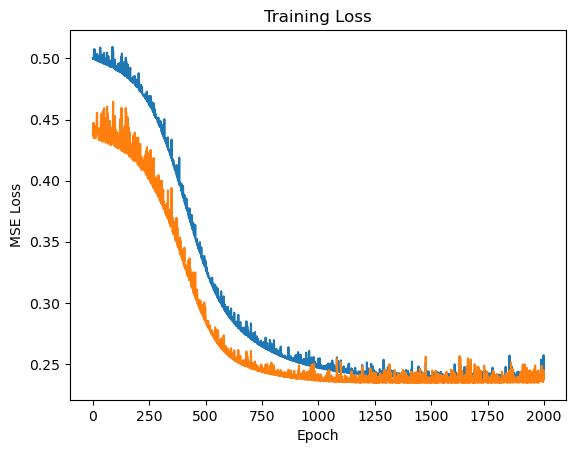

In [284]:
import matplotlib.pyplot as plt

plt.plot(train_mse_list)
plt.plot(test_mse_list)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")
plt.show()

# Analysis

Residual plot: 

R2 error, $e = y_{actual} - y_{predicted}$




In [253]:
residuals = [] # y_axis
predictions = []
for i in range(len(y_test_tensor)):
    pred = ffn(W, X_test_tensor[i].unsqueeze(1))
    predictions.append(pred.item())
    residuals.append(y_test_tensor[i].item() - pred.item())

89


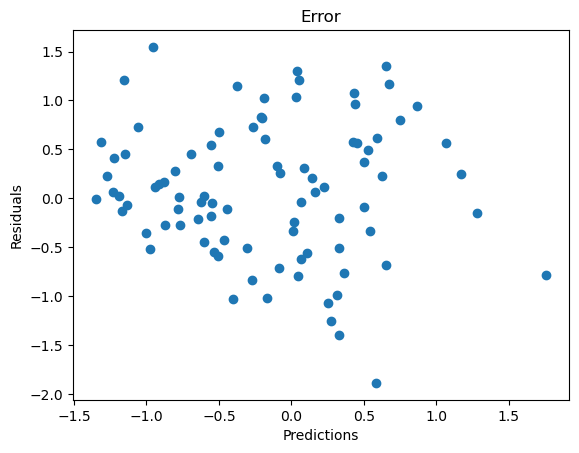

In [254]:
import matplotlib.pyplot as plt


print(len(predictions))

plt.scatter(predictions, residuals)
plt.xlabel("Predictions")
plt.ylabel("Residuals")
plt.title("Error")
plt.show()